# Projeto gmxflow

Este notebook conduz uma simulação de proteína sem ligante. A configuração científica continua em `project.toml`; revise o campo de força e os parâmetros antes de executar. O projeto remove resíduos `HOH` durante a preparação e preserva o PDB original em `inputs/`.

A API Python usada aqui ainda é experimental. A execução pode consumir bastante tempo e recursos computacionais, dependendo da configuração. Se `simulation.profile = "smoke"`, os resultados servem apenas para verificar a integração do software e não têm interpretação científica.

## 1. Abrir o projeto

Coloque os arquivos de entrada na pasta `inputs/` e ajuste os caminhos correspondentes em `project.toml`.

In [1]:
from gmxflow.api import GmxFlowProject

project = GmxFlowProject.open('project.toml')
project.edit_config()
print('Projeto aberto.')

Projeto aberto.


## 2.1 Parametrização

In [2]:
project.edit_config()

## 2. Verificar se está tudo pronto

Esta verificação confere os arquivos, o GROMACS e o campo de força. Ela não inicia a simulação.

In [3]:
project.validate()
print('Pré-requisitos verificados.')

Pré-requisitos verificados.


## 3. Executar a simulação

> Antes de executar, confira os parâmetros em `project.toml` e os arquivos em `inputs/`. Esta célula inicia a pipeline completa definida para o projeto.

In [4]:
execution_report = project.run()
project.show_execution(execution_report)

### Resumo da execução

,Etapa,Status,Duração (s),Log
0,workspace,concluída,0.000,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/00_workspace.log
1,prepare,concluída,0.775,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/01_prepare.log
2,topology,concluída,0.698,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/02_topology.log
3,box,concluída,0.009,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/03_box.log
4,solvate,concluída,0.365,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/04_solvate.log
5,ions-grompp,concluída,14.123,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/05_ions-grompp.log
6,ions,concluída,0.032,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/06_ions.log
7,em-grompp,concluída,14.167,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/07_em-grompp.log
8,em,concluída,4.907,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/08_em.log
9,nvt-grompp,concluída,13.562,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/09_nvt-grompp.log


## 4. Abrir o relatório

O relatório será exibido aqui. A versão HTML para compartilhar também fica disponível em `outputs/report.html`.

# lysozyme_in_water

Lisozima em água, baseada no tutorial introdutório do GROMACS

## Resumo

,Item,Valor
0,Perfil,standard
1,Passos de produção,50000000
2,RMSD backbone médio,0.005 +/- 0.002 nm
3,RMSD médio vs. referência minimizada,0.019 +/- 0.001 nm


## Execução

Etapas concluídas: 21 / 21

,Etapa,Status,Duração (s),Código de saída
0,workspace,success,0.000,0
1,prepare,success,0.775,0
2,topology,success,0.698,0
3,box,success,0.009,0
4,solvate,success,0.365,0
5,ions-grompp,success,14.123,0
6,ions,success,0.032,0
7,em-grompp,success,14.167,0
8,em,success,4.907,0
9,nvt-grompp,success,13.562,0


## Análises

,Métrica,Média,Desvio padrão,Mínimo,Máximo,Pontos,Fração > 0,Unidade
0,RMSD do backbone,0.004747,0.002412,0.000508,0.007876,11,None,nm
1,RMSD vs. referência minimizada,0.019272,0.000869,0.017867,0.020651,11,None,nm
2,RMSF por resíduo,0.003018,0.000626,0.001600,0.005100,129,None,nm
3,Raio de giro,1.399532,0.000152,1.399282,1.399775,11,None,nm
4,Energia potencial após minimização,-493416.933203,38195.270291,-523606.125000,-288955.468750,160,None,kJ/mol
5,Temperatura durante NVT,240.886802,59.173226,181.713577,300.060028,2,None,K
6,Pressão durante NPT,-95.986404,0.353630,-96.340034,-95.632774,2,None,bar
7,Densidade durante NPT,997.199890,0.025452,997.174438,997.225342,2,None,kg/m³


## Gráficos

### Rmsd Bb

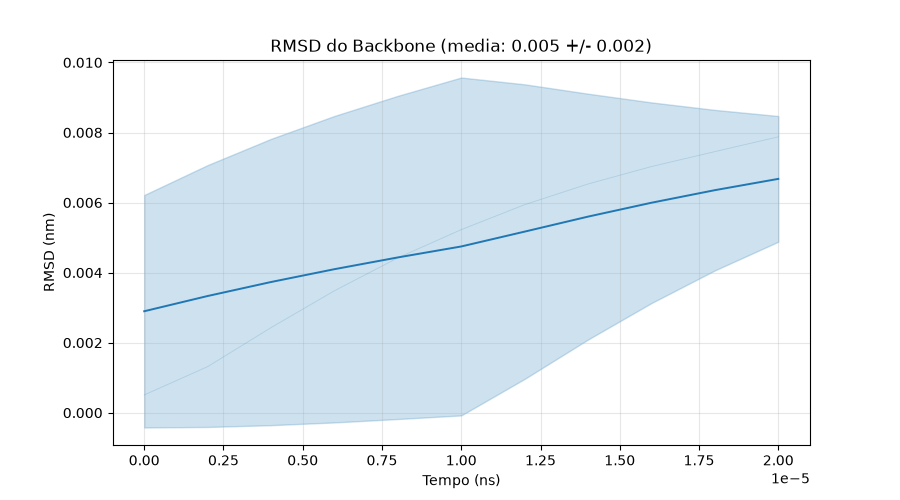

### Rmsd Reference

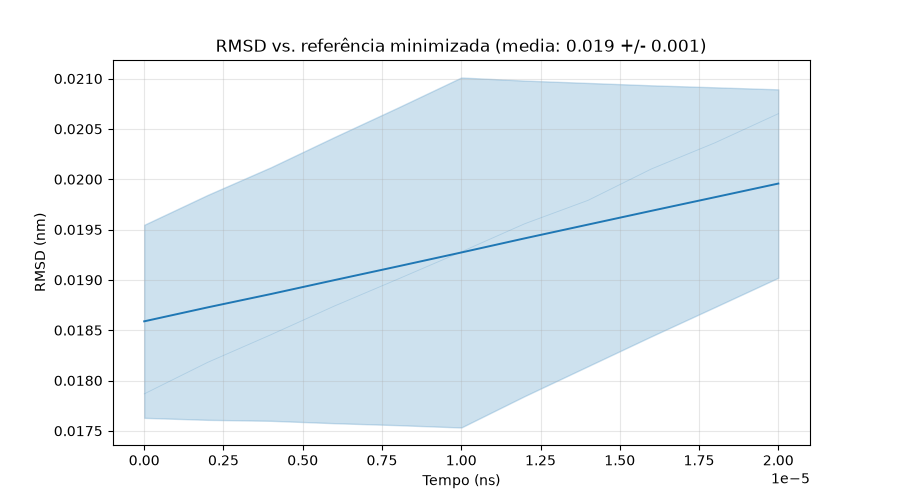

### Rmsf

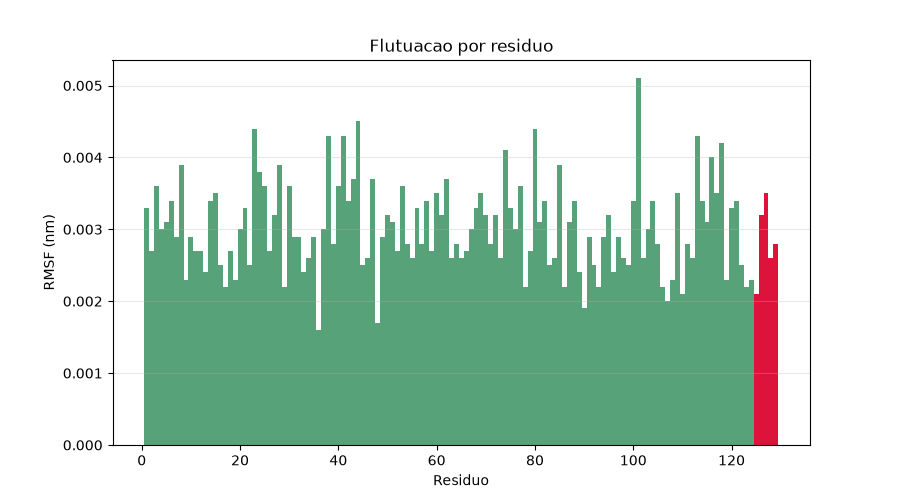

### Rg

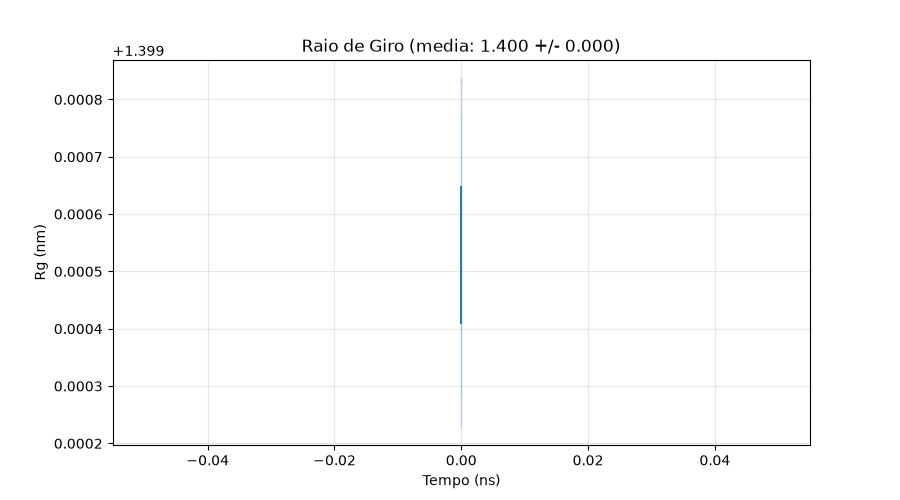

### Em Potential

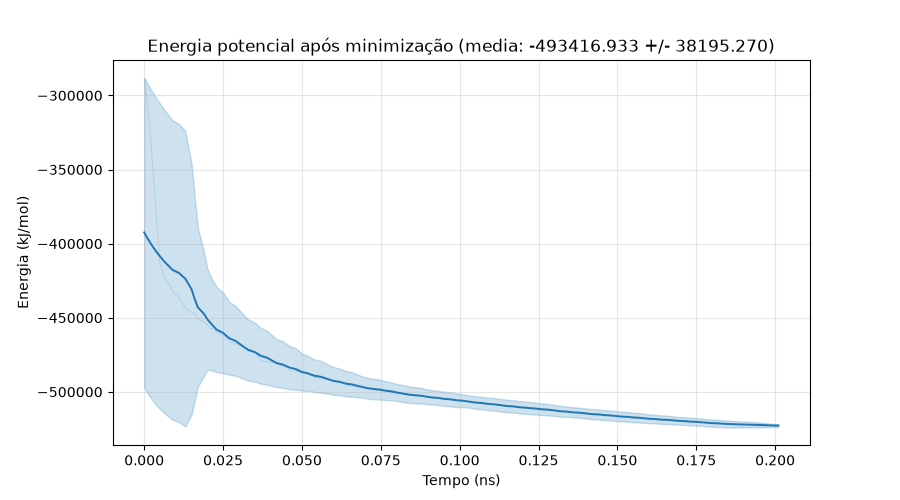

### Nvt Temperature

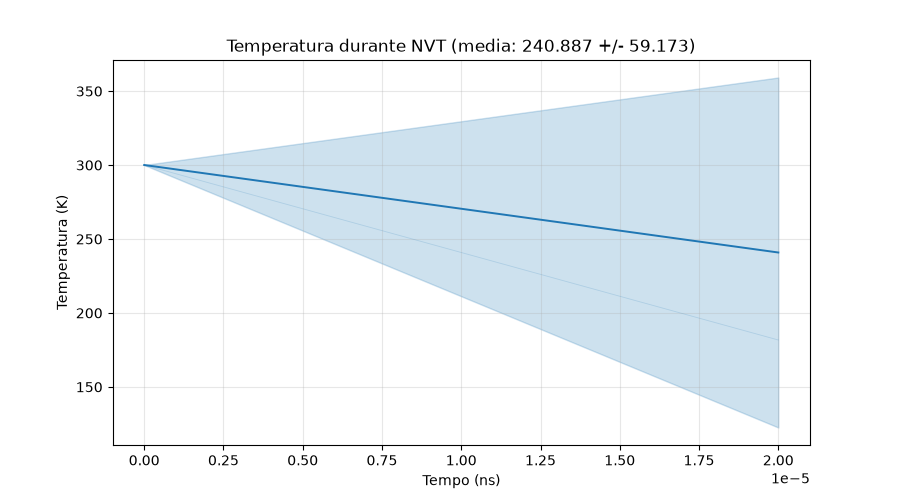

### Npt Pressure

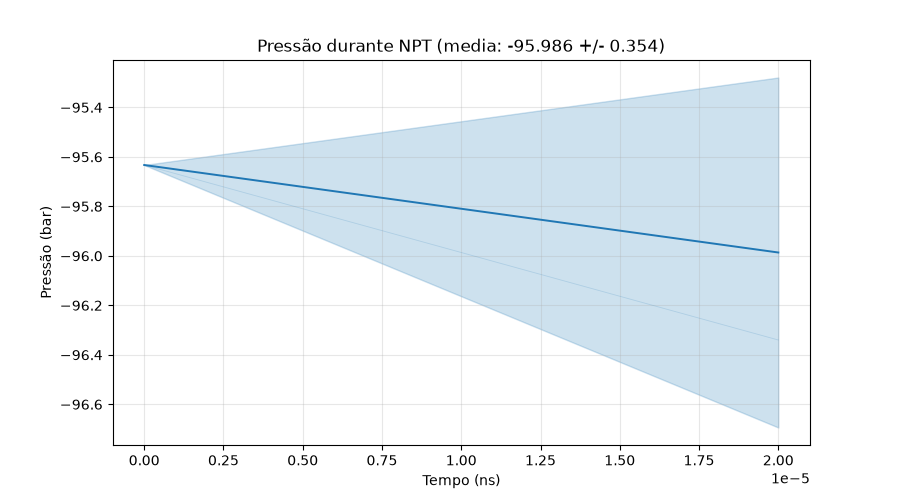

### Npt Density

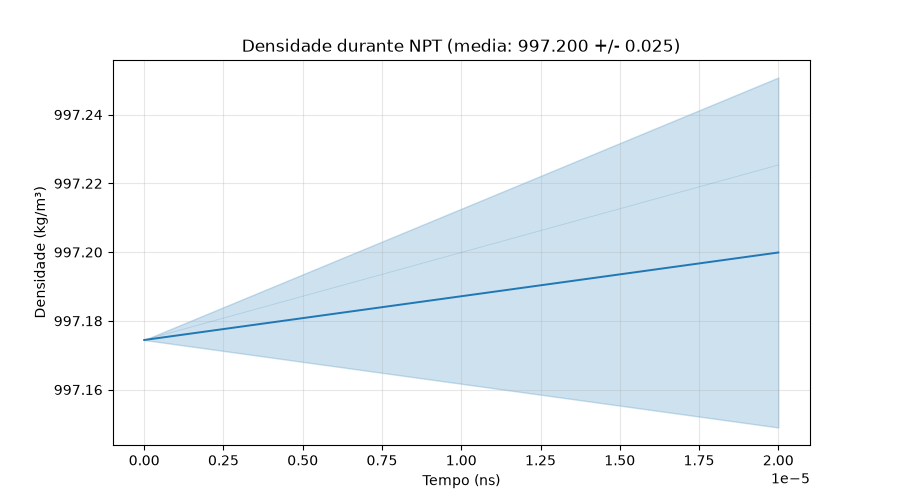

Relatório distribuível: `outputs/report.html`

In [5]:
project.show_report()